In [1]:
%% MIT 18.03 Lecture 17: Linearity, Time Invariance & RLC Dynamics
% Description: Simulates LTI system fundamentals via Control System Toolbox:
%              1) Series RLC Circuit transfer function and Bode frequency response.
%              2) Numerical validation of Time-Invariance: p(D)y(t-a) = q(t-a).
%              3) Dual exponential resonance: u'' - 4u = cosh(2t) -> u_p = (t/4)*sinh(2t).
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, lsim, bode, pole).
%
% % MBD Concept Mapping: Encapsulates operator p(D) into LTI transfer function G(s).
% %                      Demonstrates time-delay operator e^{-as} invariance and
% %                      superposition of symmetric exponential modes.


clear; clc; close all;


%% =========================================================================
%% Part 1: Series RLC Circuit Analysis via Control System Toolbox
%% =========================================================================
% Equation: L*I'' + R*I' + (1/C)*I = V'(t)
% Transfer function from source voltage V to current I: G(s) = I(s)/V(s) = s / (L*s^2 + R*s + 1/C)
L_ind = 0.5;        % Inductance (Henries)
R_res = 2.0;        % Resistance (Ohms)
C_cap = 0.05;       % Capacitance (Farads) -> 1/C = 20


% Plant Transfer Function
G_rlc = tf([1, 0], [L_ind, R_res, 1/C_cap]);


fprintf('=== Series RLC Circuit Model (Control System Toolbox) ===\n');

=== Series RLC Circuit Model (Control System Toolbox) ===

In [2]:
fprintf('LTI Transfer Function G(s) = I(s)/V(s): \n');

LTI Transfer Function G(s) = I(s)/V(s):

In [3]:
display(G_rlc);

G_rlc =
 
          s
  ------------------
  0.5 s^2 + 2 s + 20
 
Continuous-time transfer function.
Model Properties

In [4]:
fprintf('System Poles: \n');

System Poles:

In [5]:
disp(pole(G_rlc));

  -2.0000 + 6.0000i
  -2.0000 - 6.0000i

In [6]:
fprintf('=========================================================\n\n');


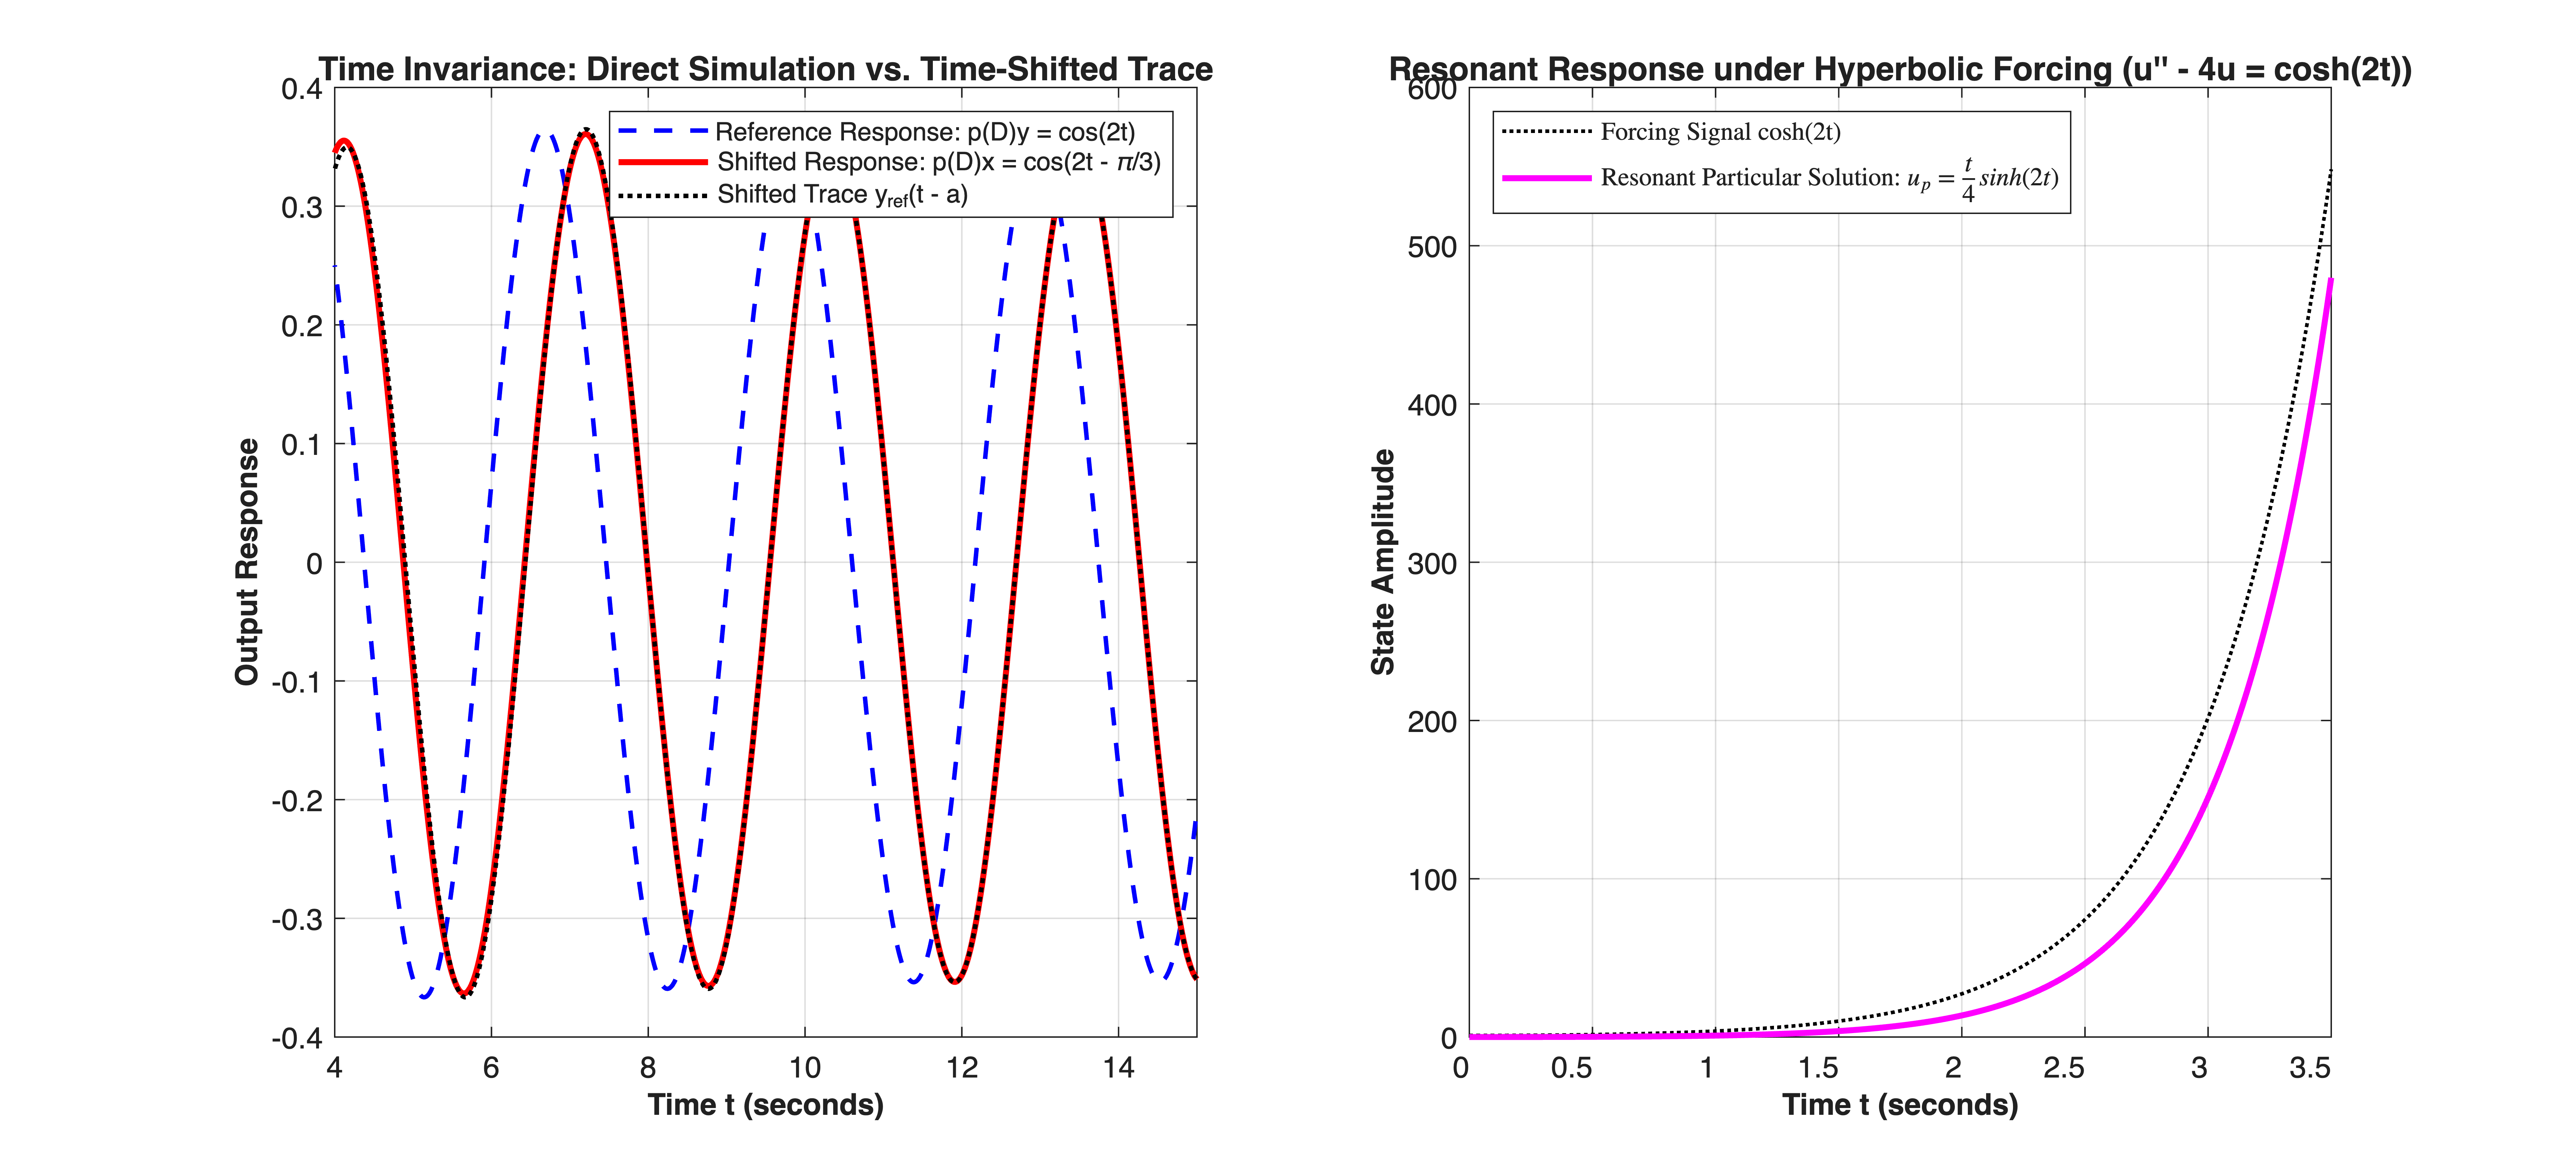

In [7]:


%% =========================================================================
%% Part 2: Time Invariance Principle Verification (Lecture Section [3])
%% =========================================================================
% Equation: x'' + x' + 6x = cos(2t - pi/3) -> a = pi/6 time delay
% Operator: p(s) = s^2 + s + 6
G_sys = tf(1, [1, 1, 6]);


% Time Grid
t_sim = linspace(0, 15, 1500);
delay_a = pi / 6; % Time delay parameter: a = pi/6 seconds


% Input 1: Unshifted reference signal q(t) = cos(2t)
u_ref = cos(2 * t_sim);


% Input 2: Shifted excitation signal q(t - a) = cos(2t - pi/3)
u_shifted = cos(2 * (t_sim - delay_a));


% Simulate responses via Control System Toolbox lsim
[y_ref, ~]     = lsim(G_sys, u_ref, t_sim);
[y_shifted, ~] = lsim(G_sys, u_shifted, t_sim);


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Time Invariance Dynamic Tracking
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_sim, y_ref, 'b--', 'LineWidth', 1.5, ...
     'DisplayName', 'Reference Response: p(D)y = cos(2t)');
plot(t_sim, y_shifted, 'r-', 'LineWidth', 2.0, ...
     'DisplayName', 'Shifted Response: p(D)x = cos(2t - \pi/3)');


% Manually shift y_ref to verify exact alignment: y_ref(t - a)
t_shifted_axis = t_sim + delay_a;
plot(t_shifted_axis, y_ref, 'k:', 'LineWidth', 1.5, ...
     'DisplayName', 'Shifted Trace y_{ref}(t - a)');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Output Response', 'FontSize', 10, 'FontWeight', 'bold');
title('Time Invariance: Direct Simulation vs. Time-Shifted Trace', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([4, 15]); % Focus on steady-state regime


%% =========================================================================
%% Part 3: Dual Exponential Resonance u'' - 4u = cosh(2t) (Section [2])
%% =========================================================================
% Characteristic polynomial: p(s) = s^2 - 4. Poles at s = +/- 2.
% Input: cosh(2t) = 0.5*exp(2t) + 0.5*exp(-2t). Both hit resonant roots!
% Analytical particular solution: u_p(t) = (t / 4) * sinh(2t)
t_res = linspace(0, 3.5, 400);
u_p_analytic = (t_res / 4) .* sinh(2 * t_res);


% Subplot 2: Hyperbolic Resonance Dynamic Growth
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_res, cosh(2 * t_res), 'k:', 'LineWidth', 1.2, ...
     'DisplayName', 'Forcing Signal cosh(2t)');
plot(t_res, u_p_analytic, 'm-', 'LineWidth', 2.0, ...
     'DisplayName', 'Resonant Particular Solution: $u_p = \frac{t}{4}sinh(2t)$');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title("Resonant Response under Hyperbolic Forcing (u'' - 4u = cosh(2t))", ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5, 'Interpreter','latex');
xlim([0, 3.5]);

In [8]:


fprintf('=== Lecture 17 Benchmark Diagnostics ===\n');

=== Lecture 17 Benchmark Diagnostics ===

In [9]:
fprintf('Complex gain at w = 2 rad/s for s^2 + s + 6:\n');

Complex gain at w = 2 rad/s for s^2 + s + 6:

In [10]:
p_2i = (1i*2)^2 + 1i*2 + 6; % 2 + 2i
fprintf('p(2i) = %+.2f %+.2fi = %.4f * exp(i * %.4f rad)\n', ...
        real(p_2i), imag(p_2i), abs(p_2i), angle(p_2i));

p(2i) = +2.00 +2.00i = 2.8284 * exp(i * 0.7854 rad)

In [11]:
fprintf('Gain = %.4f (1 / (2*sqrt(2))), Phase lag = %.4f rad (pi/4)\n', ...
        1/abs(p_2i), angle(p_2i));

Gain = 0.3536 (1 / (2*sqrt(2))), Phase lag = 0.7854 rad (pi/4)

In [12]:
fprintf('========================================\n');